In [ ]:
# ---
# title: Explore Lit2Vec Classifier Dataset
# author: Bocklitz Lab
# date: 2025-08-21
# description: Explore dataset splits, fields, licensing, and example records.
# ---

# ## 1. Setup

from datasets import load_dataset
import pandas as pd

DATASET_ID = "Bocklitz-Lab/lit2vec-subfield-classifier-dataset"

# Prefer the modern `token=` param; fall back to use_auth_token if your version needs it.
try:
    ds = load_dataset(
        DATASET_ID,
        split=None,                # get all splits if defined
        token=True,                # uses your cached HF login
        revision="main",           # avoid refs/convert/parquet unless we ask for it
        cache_dir="./.hf_cache_fresh",
        download_mode="force_redownload",
    )
except TypeError:
    # Older versions
    ds = load_dataset(
        DATASET_ID,
        split=None,
        use_auth_token=True,
        revision="main",
        cache_dir="./.hf_cache_fresh",
        download_mode="force_redownload",
    )
ds


/home/lit2vec-subfield-classifier/myenv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm

Generating train split: 31920 examples [00:01, 24834.58 examples/s]
Generating validation split: 3990 examples [00:00, 25174.64 examples/s]
Generating test split: 3990 examples [00:00, 24189.27 examples/s]


DatasetDict({
    train: Dataset({
        features: ['corpus_id', 'doi', 'url', 'title', 'authors', 'author_ids', 'venue', 'year', 'fields_of_study', 'publication_date', 'journal_name', 'license_publisher', 'license', 'oa_url', 'text', 'field_classification', 'text_type', 'embedding', 'label'],
        num_rows: 31920
    })
    validation: Dataset({
        features: ['corpus_id', 'doi', 'url', 'title', 'authors', 'author_ids', 'venue', 'year', 'fields_of_study', 'publication_date', 'journal_name', 'license_publisher', 'license', 'oa_url', 'text', 'field_classification', 'text_type', 'embedding', 'label'],
        num_rows: 3990
    })
    test: Dataset({
        features: ['corpus_id', 'doi', 'url', 'title', 'authors', 'author_ids', 'venue', 'year', 'fields_of_study', 'publication_date', 'journal_name', 'license_publisher', 'license', 'oa_url', 'text', 'field_classification', 'text_type', 'embedding', 'label'],
        num_rows: 3990
    })
})

In [2]:
# ## 2. Basic statistics

print("Splits:", ds)
print("Train size:", len(ds["train"]))
print("Validation size:", len(ds["validation"]))
print("Test size:", len(ds["test"]))


Splits: DatasetDict({
    train: Dataset({
        features: ['corpus_id', 'doi', 'url', 'title', 'authors', 'author_ids', 'venue', 'year', 'fields_of_study', 'publication_date', 'journal_name', 'license_publisher', 'license', 'oa_url', 'text', 'field_classification', 'text_type', 'embedding', 'label'],
        num_rows: 31920
    })
    validation: Dataset({
        features: ['corpus_id', 'doi', 'url', 'title', 'authors', 'author_ids', 'venue', 'year', 'fields_of_study', 'publication_date', 'journal_name', 'license_publisher', 'license', 'oa_url', 'text', 'field_classification', 'text_type', 'embedding', 'label'],
        num_rows: 3990
    })
    test: Dataset({
        features: ['corpus_id', 'doi', 'url', 'title', 'authors', 'author_ids', 'venue', 'year', 'fields_of_study', 'publication_date', 'journal_name', 'license_publisher', 'license', 'oa_url', 'text', 'field_classification', 'text_type', 'embedding', 'label'],
        num_rows: 3990
    })
})
Train size: 31920
Validation si

In [3]:
# ## 3. Inspect one example

example = ds["train"][0]
example


{'corpus_id': 16247147,
 'doi': '10.3390/molecules21091195',
 'url': 'https://www.semanticscholar.org/paper/0f73074ca2947500db3ca7e0a5d55570715d72e3',
 'title': 'Comparison of Protein N-Homocysteinylation in Rat Plasma under Elevated Homocysteine Using a Specific Chemical Labeling Method',
 'authors': ['T. Zang',
  'Ligi Paul Pottenplackel',
  'D. Handy',
  'J. Loscalzo',
  'Shujia Dai',
  'R. Deth',
  'Z. Zhou',
  'Jisheng Ma'],
 'author_ids': ['8115255',
  '89932130',
  '3374868',
  '2501779',
  '3656891',
  '2248134',
  '50252016',
  '46282292'],
 'venue': 'Molecules',
 'year': 2016,
 'fields_of_study': ['Chemistry', 'Medicine', 'Chemistry', 'Medicine'],
 'publication_date': '2016-09-01',
 'journal_name': 'Molecules',
 'license_publisher': 'MDPI AG',
 'license': 'cc-by',
 'oa_url': 'https://www.mdpi.com/1420-3049/21/9/1195/pdf?version=1473323206',
 'text': 'A selective chemical method was developed to label N-homocysteinylated proteins, revealing increased N-homocysteinylation level

In [4]:
# ## 4. Convert to pandas for quick exploration

df_train = ds["train"].to_pandas()
df_train.head(3)


,corpus_id,doi,url,title,authors,author_ids,venue,year,fields_of_study,publication_date,journal_name,license_publisher,license,oa_url,text,field_classification,text_type,embedding,label
0,16247147,10.3390/molecules21091195,https://www.semanticscholar.org/paper/0f73074c...,Comparison of Protein N-Homocysteinylation in ...,"[T. Zang, Ligi Paul Pottenplackel, D. Handy, J...","[8115255, 89932130, 3374868, 2501779, 3656891,...",Molecules,2016,"[Chemistry, Medicine, Chemistry, Medicine]",2016-09-01,Molecules,MDPI AG,cc-by,https://www.mdpi.com/1420-3049/21/9/1195/pdf?v...,A selective chemical method was developed to l...,"[Biochemistry, Medicinal Chemistry]",summary,"[0.0013429223326966166, -0.03110085241496563, ...","[7, 10]"
1,7317798,10.3390/molecules181214564,https://www.semanticscholar.org/paper/b23c2e99...,Insights into Structure-Activity Relationships...,"[Pablo Martín-Gago, E. Aragón, Marc Gomez‐Cam...","[1404788102, 121554298, 1402015991, 1402015905...",Molecules,2013,"[Chemistry, Medicine, Chemistry, Medicine]",2013-11-25,Molecules,MDPI AG,cc-by,https://www.mdpi.com/1420-3049/18/12/14564/pdf...,Somatostatin analogs containing mesitylalanine...,"[Biochemistry, Medicinal Chemistry]",summary,"[0.013775872997939587, 0.002446887781843543, -...","[7, 10]"
2,54757345,10.1155/2011/359161,https://www.semanticscholar.org/paper/753b3985...,The Characterization and Hydrogen Production f...,"[Joonwoo Kim, Hae-Ri Kim, S. Choung]","[2117059716, 2109741453, 14974970]",,2011,"[Environmental Science, Chemistry, Engineering...",2011-04-13,International Journal of Photoenergy,Hindawi Limited,cc-by,https://downloads.hindawi.com/journals/ijp/201...,The photocatalytic production of hydrogen from...,"[Catalysis, Materials Science, Energy Chemistry]",abstract,"[0.016892084851861, -0.03366902470588684, 0.02...","[0, 4, 9]"


In [6]:
# ## 6. Fields of study frequency

from collections import Counter
import itertools

fields = list(itertools.chain.from_iterable(df_train["fields_of_study"].dropna()))
Counter(fields).most_common(15)


[('Chemistry', 40434),
 ('Medicine', 33893),
 ('Biology', 11680),
 ('Materials Science', 10452),
 ('Environmental Science', 9756),
 ('Engineering', 3020),
 ('Physics', 2953),
 ('Agricultural and Food Sciences', 1986),
 ('Computer Science', 1215),
 ('Mathematics', 196),
 ('Geology', 91),
 ('Education', 79),
 ('Psychology', 70),
 ('Art', 37),
 ('Business', 25)]

<Axes: xlabel='year'>

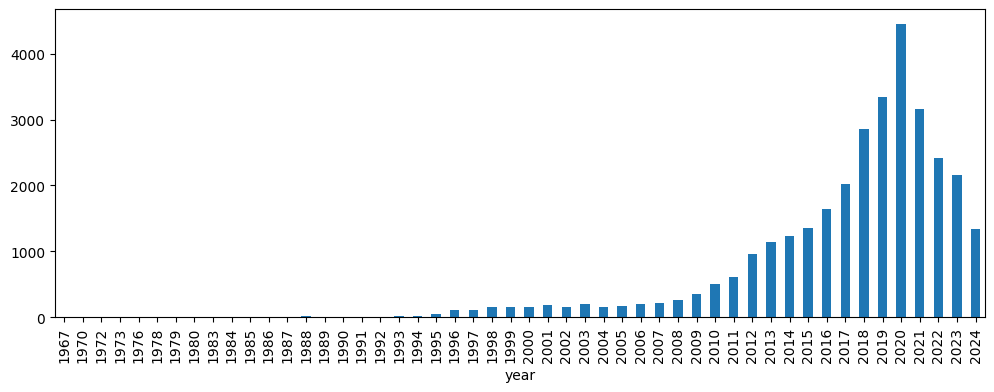

In [7]:
# ## 7. Year distribution

df_train["year"].value_counts().sort_index().plot(kind="bar", figsize=(12,4))


In [9]:
# ## 8. License check

df_train["license"].value_counts()


license
cc-by    31920
Name: count, dtype: int64

In [ ]:
# ## 9. Example: text → label pairs

for i in range(3):
    print("="*80)
    print("TITLE:", df_train.iloc[i]["title"])
    print("\ntext:\n", df_train.iloc[i]["text"])
    print("\nlabel:\n", df_train.iloc[i]["label"])


TITLE: Comparison of Protein N-Homocysteinylation in Rat Plasma under Elevated Homocysteine Using a Specific Chemical Labeling Method

text:
 A selective chemical method was developed to label N-homocysteinylated proteins, revealing increased N-homocysteinylation levels by 1.8-fold in vitamin B12 deficient rats. This suggests metabolic correlations with total homocysteine, highlighting additional metabolic factors affecting protein modifications.

label:
 [ 7 10]
TITLE: Insights into Structure-Activity Relationships of Somatostatin Analogs Containing Mesitylalanine

text:
 Somatostatin analogs containing mesitylalanine residues exhibit more restricted conformations compared to the natural hormone, with some peptides showing selective binding to somatostatin receptors and increased serum stability, while multiple incorporations of Msa reduced conformational rigidity and affinity.

label:
 [ 7 10]
TITLE: The Characterization and Hydrogen Production from Water Decomposition with Methanol 

In [13]:
# ## 10. Save small sample (for quick debugging in scripts)

sample = df_train.sample(100, random_state=42)
sample.to_json("../data/samples.jsonl", orient="records", lines=True, force_ascii=False)
print("✅ Saved 100-sample dataset to ../data/samples.jsonl")


✅ Saved 100-sample dataset to ../data/samples.jsonl
